In [4]:
!pip3 install "numpy<2" "pandas<3" matplotlib ucimlrepo

INFO: pip is looking at multiple versions of contourpy to determine which version is compatible with other requirements. This could take a while.
  Using cached contourpy-1.3.3-cp312-cp312-macosx_11_0_arm64.whl.metadata (5.5 kB)
Using cached contourpy-1.3.3-cp312-cp312-macosx_11_0_arm64.whl (273 kB)
  Attempting uninstall: contourpy
    Found existing installation: contourpy 1.4.0
    Uninstalling contourpy-1.4.0:
      Successfully uninstalled contourpy-1.4.0


In [3]:
import sys
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

print(sys.version.split()[0])
print(pd.__version__)
print(matplotlib.__version__)
print("Setup complete")

3.12.7
3.1.0
3.11.2
Setup complete


In [5]:
from ucimlrepo import fetch_ucirepo
bike_sharing = fetch_ucirepo(id=275)

# Re-combine them side-by-side
import pandas as pd
data = pd.concat([bike_sharing.data.features, bike_sharing.data.targets], axis=1)

# Confirm both features and target columns are present
print(data.columns)

Index(['dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'cnt'],
      dtype='str')


In [6]:
print(f"Rows: {len(data):,}")
print(data.head())
print("Missing values:", int(data.isna().sum().sum()))
print("Duplicate rows:", int(data.duplicated().sum()))

Rows: 17,379
       dteday  season  yr  mnth  hr  holiday  weekday  workingday  weathersit  \
0  2011-01-01       1   0     1   0        0        6           0           1   
1  2011-01-01       1   0     1   1        0        6           0           1   
2  2011-01-01       1   0     1   2        0        6           0           1   
3  2011-01-01       1   0     1   3        0        6           0           1   
4  2011-01-01       1   0     1   4        0        6           0           1   

   temp   atemp   hum  windspeed  cnt  
0  0.24  0.2879  0.81        0.0   16  
1  0.22  0.2727  0.80        0.0   40  
2  0.22  0.2727  0.80        0.0   32  
3  0.24  0.2879  0.75        0.0   13  
4  0.24  0.2879  0.75        0.0    1  
Missing values: 0
Duplicate rows: 0


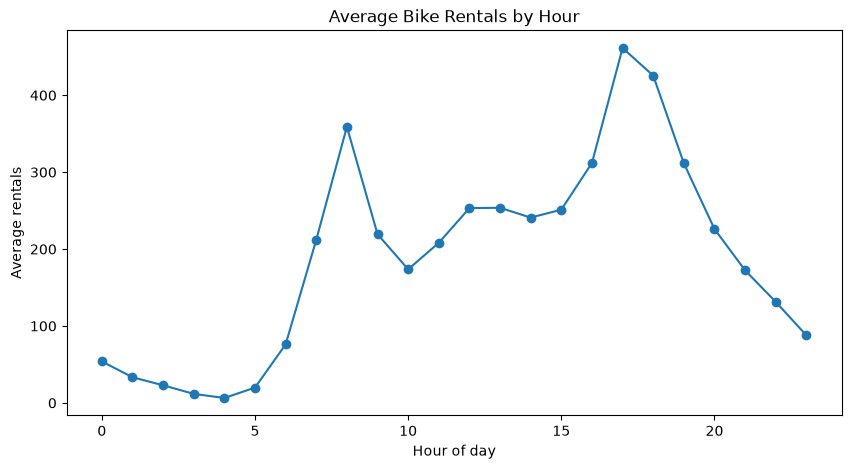

In [7]:
overall_by_hour = data.groupby("hr")["cnt"].mean()
ax = plt.subplots(figsize=(10, 5))[1]
ax.plot(overall_by_hour.index, overall_by_hour.values, marker="o")
ax.set(
    title="Average Bike Rentals by Hour",
    xlabel="Hour of day",
    ylabel="Average rentals",
)
plt.show()

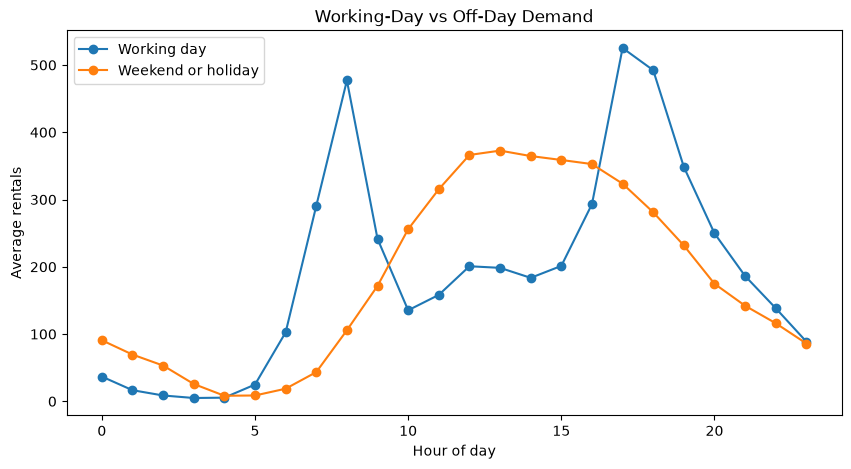

In [9]:
workday_by_hour = data[data["workingday"] == 1].groupby("hr")["cnt"].mean()
offday_by_hour = data[data["workingday"] == 0].groupby("hr")["cnt"].mean()
ax = plt.subplots(figsize=(10, 5))[1]
ax.plot(
    workday_by_hour.index,
    workday_by_hour.values,
    marker="o",
    label="Working day",
)
ax.plot(
    offday_by_hour.index,
    offday_by_hour.values,
    marker="o",
    label="Weekend or holiday",
)
ax.set(
    title="Working-Day vs Off-Day Demand",
    xlabel="Hour of day",
    ylabel="Average rentals",
)
ax.legend()
plt.show()

In [10]:
weather_labels = {
    1: "Clear or partly cloudy",
    2: "Mist or cloudy",
    3: "Light snow or rain",
    4: "Heavy rain or snow",
}
data["weather_label"] = data["weathersit"].map(weather_labels)
weather_demand = data.groupby("weather_label")["cnt"].mean()

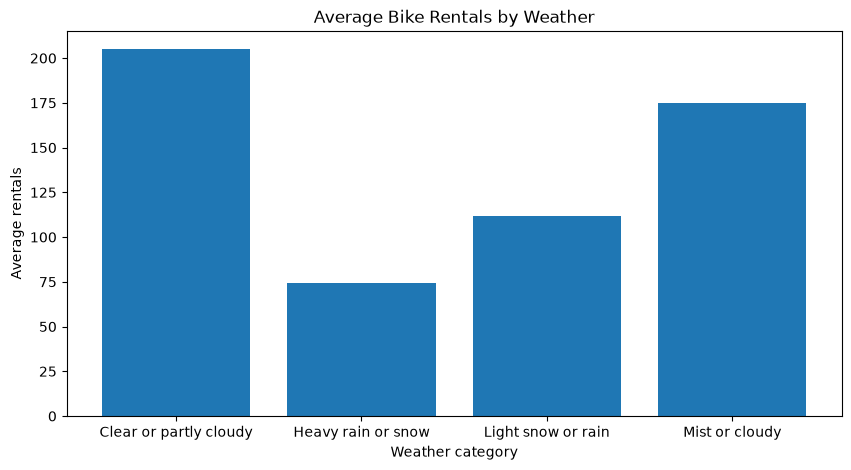

In [11]:
ax = plt.subplots(figsize=(10, 5))[1]
ax.bar(weather_demand.index, weather_demand.values)
ax.set(
    title="Average Bike Rentals by Weather",
    xlabel="Weather category",
    ylabel="Average rentals",
)
plt.show()

In [12]:
peak_workday_hour = int(workday_by_hour.idxmax())
peak_offday_hour = int(offday_by_hour.idxmax())
highest_demand_weather = weather_demand.idxmax()

In [13]:
print("Operational recommendation")
print(
    f"Prioritize bikes and staff around {peak_workday_hour}:00 on working days."
)
print(
    f"Use a separate off-day plan centered around {peak_offday_hour}:00."
)
print(
    "Average demand is highest during "
    f"{highest_demand_weather.lower()} conditions."
)

Operational recommendation
Prioritize bikes and staff around 17:00 on working days.
Use a separate off-day plan centered around 13:00.
Average demand is highest during clear or partly cloudy conditions.
